In [ ]:
# Approved additional library 
%pip install PyPortfolioOpt

In [19]:
# These are the libraries you may use for this assignment.
# If you would like to use any other libraries, email james@uwaterloo.ca for permission first.
# Generative AI tools (including coding assistants) are not permitted for this assignment.

from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime
import math


## CFM 101 — Group Assignment 2026
### Robo-Advising Challenge: Two Clients, Two Strategies

**Team Number:** XX  
**Team Member Names (three or four):**  

Enter the names of all participating members below (one name per line):

**Submission:** Friday, November 27, 2026, at 9:00 AM (Eastern), via Dropbox.  
**Submit this completed Jupyter notebook only.**

Your team must construct **both** portfolios from the supplied `Tickers.csv` file:

- **Client A — Growth:** $\$1,000,000$ CAD; seek the highest expected return.
- **Client B — Low Risk:** $\$750,000$ CAD; seek the lowest portfolio volatility.

Both clients require 10–20 eligible stocks, at most 15% in any stock and at most 40% in any sector. Read the full assignment handout for all eligibility, fee, currency, and competition rules. Do not hardcode the selected stocks. Check that tickers are valid. The supplied ticker universe will permit feasible portfolios.

**No generative AI may be used in preparing this assignment.**

## Data preparation and shared functions

Read `Tickers.csv`, check ticker eligibility, retrieve the data needed for your strategies, and create any functions you will reuse for both clients. Use closing prices from **November 27, 2026** for the purchase calculations. All portfolio values and weights must be calculated in CAD, with purchase fees paid from the client budget.

In [20]:

import time # not in the given import cell above, but needed for time.sleep

# Group and ticker file
GROUP_NUMBER = "6"        
TICKER_FILE = "Tickers.csv"

# Purchase date
PURCHASE_DATE = pd.Timestamp("2026-11-27")


# Competition holding window (used to find earnings reports during the competition)
HOLD_START = pd.Timestamp("2026-11-27 16:00", tz="America/New_York")
HOLD_END   = pd.Timestamp("2026-12-04 16:00", tz="America/New_York")

# Price history to download: must start before the volume window and cover a year of signals
HISTORY_START = pd.Timestamp("2024-10-01")

# Volume rule
VOLUME_START = pd.Timestamp("2025-10-01")
VOLUME_END   = pd.Timestamp("2026-09-30")
MIN_AVG_VOLUME = 5000
MIN_TRADING_DAYS_IN_MONTH = 18

# Client budgets in CAD
CLIENT_BUDGETS = {"A": 1_000_000, "B": 750_000}

# Number of stocks chosen for each client
CLIENT_N_STOCKS = {"A": 12, "B": 16}                   

# Portfolio rules
MIN_STOCKS = 10
MAX_STOCKS = 20
MAX_STOCK_WEIGHT = 0.15
MAX_SECTOR_WEIGHT = 0.40

# Transaction fee: the smaller of US$2.15 and US$0.001 per share, for every stock
MAX_FEE_USD = 2.15
FEE_PER_SHARE_USD = 0.001
 ## leave one cent unspent so rounding can never exceed the budget
SAFETY_BUFFER_CAD = 0.01    

# Allowed security type and currencies (yfinance codes)
ALLOWED_QUOTE_TYPES = ["EQUITY"]
ALLOWED_CURRENCIES  = ["CAD", "USD"]

# US exchanges: Nasdaq tier 
US_EXCHANGES = ["NMS", "NGM", "NCM", "NYQ", "ASE", "PCX", "BTS"]  # Nasdaq tiers, NYSE, NYSE American, NYSE Arca, Cboe
CA_EXCHANGES = ["TOR", "VAN", "NEO", "CNQ"]                       # TSX, TSX Venture, Cboe Canada, CSE

# OTC / pink-sheet codes are deliberately excluded: they are not exchange listings.
MAX_STALE_DAYS = 5           # last price older than this before the purchase date = not trading

# Strategy settings
TRADING_DAYS_PER_YEAR = 252
LOOKBACK_DAYS = 252          # one year: Client B volatility and the equal-weight comparison period
MOMENTUM_DAYS = 126          # about six months
SHORT_MOMENTUM_DAYS = 20     # about one month
TREND_DAYS = 50              # 50-day moving average trend filter
CATALYST_BONUS = 0.10        # score bonus for Client A stocks with earnings in the window and positive momentum

# Benchmarks: S&P 500 and S&P/TSX Composite
BENCHMARK_TICKERS = {"US": "^GSPC", "CA": "^GSPTSE"}  # S&P 500 and S&P/TSX Composite

# Exchange rate: CAD per 1 USD
FX_TICKER = "CAD=X"          # CAD per 1 USD

# Pause function between yfinance requests so no rate limited
PAUSE_SECONDS = 0.2        





# Read the ticker file and collect company information

# Read the ticker file and return a list with no duplicates

def read_tickers(path):
    
    # Read the ticker file (one ticker per row, no header) 
    raw = pd.read_csv(path, header=None)

    tickers = []

    for ticker in raw.iloc[:, 0].dropna():
        ticker = str(ticker).strip().upper()

        # Skip blank rows and tickers already in the list 
        if ticker != "" and ticker not in tickers:
            tickers.append(ticker)

    return tickers



# Get the security type, exchange, currency, sector and name of each ticker
def get_stock_info(tickers):
   
    rows = []
    for ticker in tickers: # If yfinance cannot find the ticker, its values stay empty
        
        try:
            info = yf.Ticker(ticker).info
        except Exception:
            info = {}
        
        rows.append({
            "Ticker": ticker,
            "SecurityType": info.get("quoteType"),
            "Exchange": info.get("exchange"),
            "Currency": info.get("currency"),
            "Sector": info.get("sector"),
            "Name": info.get("longName") or info.get("shortName"),
        })
        time.sleep(PAUSE_SECONDS)
    stock_info = pd.DataFrame(rows).set_index("Ticker")
    
    return pd.DataFrame(rows).set_index("Ticker")

# Return "US", "CA" or None depending on where the stock is listed
def market_of(exchange):
    
    if pd.isna(exchange):
        return None
    if exchange in US_EXCHANGES:
        return "US"
    if exchange in CA_EXCHANGES:
        return "CA"
    return None



# Download price and volume history

# Download daily closing prices and volumes (dates x tickers)


def download_history(tickers, start, end):
    data = yf.download(tickers, start=start, end=end + pd.Timedelta(days=1),
                       auto_adjust=False, progress=False, group_by="column")

    
    closes = data["Close"]
    volumes = data["Volume"]
    
    # With one ticker yfinance can return a Series; make it a DataFrame either way
    if isinstance(closes, pd.Series):
        closes = closes.to_frame(tickers[0])
        volumes = volumes.to_frame(tickers[0])
        
    # Remove time zone from the dates
    closes.index = pd.to_datetime(closes.index).tz_localize(None)
    volumes.index = pd.to_datetime(volumes.index).tz_localize(None)
    
    return closes, volumes 


# Get the exchange rate (CAD per USD) on the same dates as the stocks
def get_fx_rate(index, start, end):

    # Download the exchange rate closes
    fx = yf.download(FX_TICKER, start=start, end=end + pd.Timedelta(days=1),
                     auto_adjust=False, progress=False)["Close"]
    
    # yfinance can return a one-column DataFrame, take the column
    if isinstance(fx, pd.DataFrame):
        fx = fx.iloc[:, 0]
        
    # Remove the time zone from the dates
    fx.index = pd.to_datetime(fx.index).tz_localize(None)

    # Line up with the stock dates
    all_dates = fx.index.union(index) 
    fx = fx.reindex(all_dates).ffill()
    fx = fx.reindex(index)

    fx = fx.rename("USDCAD")

    return fx



# Convert USD prices to CAD; CAD prices stay the same
def convert_to_cad(closes_local, currencies, fx):
    
    prices_cad = closes_local.copy()
    for ticker in closes_local.columns:
        if currencies.get(ticker) == "USD":
            prices_cad[ticker] = closes_local[ticker] * fx
   
    return prices_cad




# Volume Rule

# A "trading day" is a day the stock actually has a volume record. Because TSX and US holidays differ, each stock is counted on its own calendar.
# The average is taken over all remaining days (not an average of monthly averages).


def average_volume(volume_series, start, end, min_days):

    # Volumes inside the window
    v = volume_series.loc[start:end].dropna()
    
    if v.empty:
        return np.nan
    
    # Count the trding days in each month
    month = v.index.to_period("M")
    days_per_month = v.groupby(month).count()

    # Keep the months with enough trading days
    full_months = []

    for m in days_per_month.index:
        if days_per_month[m] >= min_days:
            full_months.append(m)

    
    v = v[month.isin(full_months)]

    if v.empty:
        return np.nan

    return v.mean()


# Eligibility check plus load_stock_data()

# Add the Market, AvgVolume, Eligible and Reason columns

def check_eligibility(info, closes_local, volumes, as_of):
    
    result = info.copy()
    result["Market"] = result["Exchange"].apply(market_of)
    result["AvgVolume"] = np.nan
    result["Eligible"] = False
    result["Reason"] = ""

    # Check the last price against the purchase date
    for ticker in result.index:
        problems = []
        row = result.loc[ticker]

        if pd.isna(row["SecurityType"]):
            # yfinance found nothing: report one clear reason and skip the other checks
            result.loc[ticker, "Reason"] = "invalid ticker (no data found)"
            continue

        # Security type    
        if row["SecurityType"] not in ALLOWED_QUOTE_TYPES:
            problems.append(f"not a company stock ({row['SecurityType']})")
        
        # Exchange
        if pd.isna(row["Market"]):
            problems.append(f"not listed on a Canadian/US exchange ({row['Exchange']})")
        
        # Currency
        if row["Currency"] not in ALLOWED_CURRENCIES:
            problems.append(f"currency not CAD/USD ({row['Currency']})")

        if ticker in closes_local.columns:
            prices = closes_local[ticker].dropna()
            last_date = prices.index.max() if not prices.empty else None
            check_date = min(as_of, pd.Timestamp.today().normalize())
            if last_date is None or (check_date - last_date).days > MAX_STALE_DAYS:
                problems.append("no recent price (possibly delisted)")
            avg_vol = average_volume(volumes[ticker], VOLUME_START, VOLUME_END,
                                     MIN_TRADING_DAYS_IN_MONTH)
            result.loc[ticker, "AvgVolume"] = avg_vol
            if pd.isna(avg_vol) or avg_vol < MIN_AVG_VOLUME:
                problems.append(f"average volume below {MIN_AVG_VOLUME:,}")
        else:
            problems.append("no price data")

        result.loc[ticker, "Eligible"] = len(problems) == 0
        result.loc[ticker, "Reason"] = "; ".join(problems)
    return result


# Read the tickers, check eligibility and download the history
# Returns a dictionary with the screening table and all the price tables
def load_stock_data(path, as_of=PURCHASE_DATE):

    # Read the tickers
    tickers = read_tickers(path)
    print("Read", len(tickers), "unique tickers from", path)

    # Get company information
    info = get_stock_info(tickers)

    # Only download prices for tickers yfinance found
    found = []

    for ticker in tickers:
        if pd.notna(info.loc[ticker, "SecurityType"]):
            found.append(ticker)

    closes_local, volumes = download_history(found, HISTORY_START, as_of)

    # Check eligibility
    screening = check_eligibility(info, closes_local, volumes, as_of)
    eligible = list(screening.index[screening["Eligible"]])

    # Keep only eligible stocks in the price tables
    closes_local = closes_local[eligible].loc[:as_of]
    volumes = volumes[eligible].loc[:as_of]

    # Convert prices to CAD
    fx = get_fx_rate(closes_local.index, HISTORY_START, as_of)
    prices_cad = convert_to_cad(closes_local, screening["Currency"].to_dict(), fx)

    print(len(eligible), "eligible,", len(tickers) - len(eligible), "excluded")

    return {
        "screening": screening,
        "eligible": eligible,
        "closes_local": closes_local,
        "volumes": volumes,
        "fx": fx,
        "prices_cad": prices_cad,
    }


# Benchmarks in CAD

# Each stock is compared with its home market

# Return a DataFrame with "US" and "CA" columns, both in CAD, on the same dates as the stocks
def get_benchmarks_cad(index, fx, start, end):

    # Download the two index closes
    symbols = list(BENCHMARK_TICKERS.values())
    closes, volumes = download_history(symbols, start, end)

    # Line up with the stock dates, using the last value on holidays
    all_dates = closes.index.union(index)
    closes = closes.reindex(all_dates).ffill()
    closes = closes.reindex(index)

    benchmark_cad = pd.DataFrame(index=index)

    # S&P 500 is in USD, so convert it to CAD
    benchmark_cad["US"] = closes[BENCHMARK_TICKERS["US"]] * fx

    # TSX is already in CAD
    benchmark_cad["CA"] = closes[BENCHMARK_TICKERS["CA"]]

    return benchmark_cad





# Catalysts (earnings reports during the holding window)

# Return the first earnings date inside the window, or NaT if there is none
def earnings_in_window(timestamps, start=HOLD_START, end=HOLD_END):

    for ts in sorted(timestamps):

        # Put every date in New York time
        ts = pd.Timestamp(ts)
        if ts.tzinfo is None:
            ts = ts.tz_localize("America/New_York")
        else:
            ts = ts.tz_convert("America/New_York")

        # If the time is unknown (midnight), compare the dates only
        if ts.hour == 0 and ts.minute == 0:
            if start.date() < ts.date() <= end.date():
                return ts
        elif start < ts < end:
            return ts

    return pd.NaT


# Get earnings dates from get_earnings_dates(), or from .calendar if that gives nothing
def get_earnings_timestamps(ticker):

    stock = yf.Ticker(ticker)
    timestamps = []

    try:
        dates = stock.get_earnings_dates(limit=8)
        if dates is not None and len(dates) > 0:
            timestamps = timestamps + list(dates.index)
    except Exception:
        pass

    if len(timestamps) == 0:
        try:
            calendar = stock.calendar
            if not calendar:
                calendar = {}
            timestamps = timestamps + list(calendar.get("Earnings Date", []))
        except Exception:
            pass

    return timestamps



# Return a DataFrame with EarningsDate and CatalystStatus for each ticker
def get_catalysts(tickers):

    rows = []

    for ticker in tickers:

        timestamps = get_earnings_timestamps(ticker)
        hit = earnings_in_window(timestamps)

        # Only say "NoEvent" if we can see an upcoming date
        # (otherwise the data may just be out of date)
        if pd.notna(hit):
            status = "Event"
        elif len(timestamps) == 0:
            status = "Unknown"
        else:

            # Find the latest earnings date yfinance gave us (without time zone)
            latest = None

            for t in timestamps:
                t = pd.Timestamp(t)
                if t.tzinfo is not None:
                    t = t.tz_convert(None)
                if latest is None or t > latest:
                    latest = t

            if latest > HOLD_START.tz_convert(None):
                status = "NoEvent"
            else:
                status = "Unknown"

        rows.append({"Ticker": ticker, "EarningsDate": hit, "CatalystStatus": status})

        time.sleep(PAUSE_SECONDS)

    catalysts = pd.DataFrame(rows).set_index("Ticker")

    return catalysts


# Signals (volatility, momentum and volume)

# Return over the last "days" trading days
def window_return(prices, days):

    if len(prices) <= days:
        return np.nan

    return prices.iloc[-1] / prices.iloc[-1 - days] - 1


# Calculate the signals for each ticker as of the as_of date (one row per ticker)
def calculate_signals(prices_cad, volumes, benchmark_cad, markets, as_of=PURCHASE_DATE):

    # Only use data up to as_of
    prices_cad = prices_cad.loc[:as_of]
    volumes = volumes.loc[:as_of]
    benchmark_cad = benchmark_cad.loc[:as_of]

    # Benchmark 20-day returns, using each benchmark's own trading days
    bench_return20 = {}

    for market in benchmark_cad.columns:
        bench_return20[market] = window_return(benchmark_cad[market].dropna(), 20)

    rows = []

    for ticker in prices_cad.columns:

        prices = prices_cad[ticker].dropna()
        daily_returns = prices.pct_change().dropna()
        vol = volumes[ticker].dropna()

        # 20-day and 60-day volatility
        if len(daily_returns) >= 20:
            vol20 = daily_returns.tail(20).std()
        else:
            vol20 = np.nan

        if len(daily_returns) >= 60:
            vol60 = daily_returns.tail(60).std()
        else:
            vol60 = np.nan

        if vol60:
            vol_ratio = vol20 / vol60
        else:
            vol_ratio = np.nan

        # 20-day return and price compared with its 20-day average
        return20 = window_return(prices, 20)

        if len(prices) >= 20:
            ma20 = prices.tail(20).mean()
        else:
            ma20 = np.nan

        if ma20:
            price_vs_ma20 = prices.iloc[-1] / ma20 - 1
        else:
            price_vs_ma20 = np.nan

        # 20-day return compared with the stock's home market
        bench = bench_return20.get(markets.get(ticker), np.nan)
        relative_momentum = return20 - bench

        # Last 5 days of volume compared with the 60-day average
        if len(vol) >= 60:
            avg_vol_60 = vol.tail(60).mean()
        else:
            avg_vol_60 = np.nan

        if avg_vol_60:
            relative_volume = vol.tail(5).mean() / avg_vol_60
        else:
            relative_volume = np.nan

        rows.append({
            "Ticker": ticker,
            "Vol20": vol20,
            "Vol60": vol60,
            "VolRatio": vol_ratio,
            "Return5": window_return(prices, 5),
            "Return20": return20,
            "PriceVsMA20": price_vs_ma20,
            "RelativeMomentum": relative_momentum,
            "RelativeVolume": relative_volume,
        })

    signals = pd.DataFrame(rows).set_index("Ticker")

    # Percentile ranks (0 to 1) so the signals can be compared in Zac's scoring
    for column in ["Vol20", "Return20", "RelativeMomentum", "RelativeVolume"]:
        signals[column + "Rank"] = signals[column].rank(pct=True)

    return signals



# Run the data prep

data = load_stock_data(TICKER_FILE)
screening = data["screening"]

# Show which tickers were excluded and why
exclusions = screening.loc[~screening["Eligible"],
                           ["SecurityType", "Exchange", "Currency", "Reason"]]

print('')
print("Excluded", len(exclusions), "tickers:")
display(exclusions)

Read 40 unique tickers from Tickers.csv


$RTN: possibly delisted; no timezone found
$MON: possibly delisted; no timezone found
$CELG: possibly delisted; no timezone found
$AGN: possibly delisted; no timezone found
$BK: possibly delisted; no price data found  (1d 2024-10-01 00:00:00 -> 2026-11-26 00:00:00)

5 Failed downloads:
['RTN', 'MON', 'CELG', 'AGN']: possibly delisted; no timezone found
['BK']: possibly delisted; no price data found  (1d 2024-10-01 00:00:00 -> 2026-11-26 00:00:00)


35 eligible, 5 excluded

Excluded 5 tickers:


,SecurityType,Exchange,Currency,Reason
Ticker,,,,
AGN,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
BK,EQUITY,NYQ,NaN,currency not CAD/USD (nan); no recent price (p...
CELG,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
MON,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
RTN,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...


## Client A — Growth

Construct a portfolio intended to achieve the **highest expected return**. Use your selected stocks and portfolio weights to create a DataFrame named `Portfolio_Final_A` with index **1 through n** and columns (in this order): `Ticker`, `Price`, `Currency`, `Shares`, `Value`, `Weight`. `Price` is in the stock’s quoted currency, `Value` is in CAD, and `Weight` is a fraction summing to 1.

In [21]:
# Long-term return and risk indicators, using CAD prices
prices = data["prices_cad"]
VOL_DAYS = 60


def stock_scores(day):
    rows = []
    for ticker in data["eligible"]:
        p = prices[ticker].loc[:day].dropna()
        if len(p) < VOL_DAYS + 1 or day not in p.index:
            continue
        sector = screening.loc[ticker, "Sector"]
        if pd.isna(sector):
            continue

        six_month = np.nan
        one_year = np.nan
        if len(p) > MOMENTUM_DAYS:
            six_month = p.iloc[-1] / p.iloc[-MOMENTUM_DAYS - 1] - 1
        if len(p) > LOOKBACK_DAYS:
            one_year = p.iloc[-1] / p.iloc[-LOOKBACK_DAYS - 1] - 1

        rows.append({
            "Ticker": ticker,
            "Sector": sector,
            "SixMonth": six_month,
            "OneYear": one_year,
            "Trend": p.iloc[-1] / p.tail(TREND_DAYS).mean() - 1,
            "Volatility": p.pct_change().tail(VOL_DAYS).std()
        })

    if len(rows) < MIN_STOCKS:
        raise ValueError("Not enough stocks with usable price history")

    s = pd.DataFrame(rows).set_index("Ticker")
    # Rank returns and trends against the other eligible stocks
    s["OneYearRank"] = s["OneYear"].rank(pct=True).fillna(0.5)
    s["SixMonthRank"] = s["SixMonth"].rank(pct=True).fillna(0.5)
    s["PriceScore"] = (0.30 * s["OneYearRank"]
                       + 0.25 * s["SixMonthRank"]
                       + 0.10 * s["Trend"].rank(pct=True)
                       + 0.05 * (1 - s["Volatility"].rank(pct=True)))

    # Choose a diverse pool before checking fundamentals
    candidates = []
    counts = {}
    ranked = s.sort_values("PriceScore", ascending=False)
    for ticker in ranked.index:
        sector = s.loc[ticker, "Sector"]
        if counts.get(sector, 0) >= int(MAX_STOCKS * MAX_SECTOR_WEIGHT):
            continue
        candidates.append(ticker)
        counts[sector] = counts.get(sector, 0) + 1
        if len(candidates) == MAX_STOCKS:
            break
    s = s.loc[candidates].copy()
    if len(s) < MIN_STOCKS:
        raise ValueError("Not enough candidates from different sectors")

    # Check the same fundamental ratios for every candidate
    s["PE"] = np.nan
    s["PB"] = np.nan
    s["ROE"] = np.nan
    s["LossMaking"] = False
    for ticker in candidates:
        try:
            info = yf.Ticker(ticker).info
        except Exception:
            info = {}
        pe = info.get("trailingPE")
        pb = info.get("priceToBook")
        roe = info.get("returnOnEquity")
        eps = info.get("trailingEps")
        if isinstance(pe, (int, float)) and np.isfinite(pe) and pe > 0:
            s.loc[ticker, "PE"] = pe
        if isinstance(pb, (int, float)) and np.isfinite(pb) and pb > 0:
            s.loc[ticker, "PB"] = pb
        if isinstance(roe, (int, float)) and np.isfinite(roe):
            s.loc[ticker, "ROE"] = roe
        if isinstance(eps, (int, float)) and np.isfinite(eps) and eps <= 0:
            s.loc[ticker, "LossMaking"] = True
        if isinstance(pe, (int, float)) and np.isfinite(pe) and pe <= 0:
            s.loc[ticker, "LossMaking"] = True
        time.sleep(PAUSE_SECONDS)

    # Lower positive P/E and P/B are better; losses get a low P/E score
    s["PEScore"] = s["PE"].rank(pct=True, ascending=False).fillna(0.5)
    s.loc[s["LossMaking"], "PEScore"] = 0
    s["Growth"] = (s["PriceScore"]
                   + 0.15 * s["ROE"].rank(pct=True).fillna(0.5)
                   + 0.10 * s["PEScore"]
                   + 0.05 * s["PB"].rank(pct=True, ascending=False).fillna(0.5))
    return s

In [22]:
# Select the highest-ranked stocks, keeping sector and stock limits

def select_stocks(s):
    ranked = s.sort_values("Growth", ascending=False)
    sizes = list(range(CLIENT_N_STOCKS["A"], MAX_STOCKS + 1))
    sizes.extend(range(MIN_STOCKS, CLIENT_N_STOCKS["A"]))

    for n in sizes:
        chosen = []
        counts = {}
        for ticker in ranked.index:
            sector = s.loc[ticker, "Sector"]
            if counts.get(sector, 0) >= int(n * MAX_SECTOR_WEIGHT):
                continue
            chosen.append(ticker)
            counts[sector] = counts.get(sector, 0) + 1
            if len(chosen) == n:
                break
        if len(chosen) != n:
            continue

        # Begin with half the budget equally weighted, then favour higher scores
        weights = pd.Series(0.5 / n, index=chosen)
        for ticker in chosen:
            sector = s.loc[ticker, "Sector"]
            same = []
            for t in chosen:
                if s.loc[t, "Sector"] == sector:
                    same.append(t)
            extra = min(1 - weights.sum(), MAX_STOCK_WEIGHT - weights[ticker],
                        MAX_SECTOR_WEIGHT - weights[same].sum())
            if extra > 0:
                weights[ticker] = weights[ticker] + extra
        if np.isclose(weights.sum(), 1):
            return chosen, weights

    raise ValueError("Could not build a valid Client A portfolio")

In [23]:
# Construct the long-term growth portfolio using the purchase-day closing prices
# The TA must run this after November 27 closing prices are available
day = PURCHASE_DATE
if day not in prices.index:
    raise ValueError("November 27 closing prices are not available yet")

s = stock_scores(day)
chosen, weights = select_stocks(s)
cad = prices.loc[day, chosen]
local = data["closes_local"].loc[day, chosen]
fx = float(data["fx"].loc[day])
if cad.isna().any() or local.isna().any() or pd.isna(fx) or fx <= 0:
    raise ValueError("Missing closing prices or exchange rate")

budget = CLIENT_BUDGETS["A"]
money = budget - SAFETY_BUFFER_CAD

# Fees depend on shares, and shares depend on the money left after fees
for i in range(5):
    shares = money * weights / cad
    fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * shares).sum() * fx
    money = budget - fees - SAFETY_BUFFER_CAD

shares = money * weights / cad
fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * shares).sum() * fx
Portfolio_Final_A = pd.DataFrame({
    "Ticker": chosen,
    "Price": local.values,
    "Currency": screening.loc[chosen, "Currency"].values,
    "Shares": shares.values,
    "Value": (shares * cad).values,
    "Weight": weights.values
}, index=range(1, len(chosen) + 1))

# Check the portfolio before displaying it
sector_weights = weights.groupby(screening.loc[chosen, "Sector"]).sum()
assert MIN_STOCKS <= len(chosen) <= MAX_STOCKS
assert set(chosen).issubset(data["eligible"])
assert weights.max() <= MAX_STOCK_WEIGHT + 0.0000001
assert sector_weights.max() <= MAX_SECTOR_WEIGHT + 0.0000001
assert np.isclose(weights.sum(), 1)
assert Portfolio_Final_A["Value"].sum() + fees <= budget

print("Purchase date:", day.date())
display(Portfolio_Final_A)
print("Fees:", round(fees, 2))
print("Cash left:", round(budget - Portfolio_Final_A["Value"].sum() - fees, 2))

Purchase date: 2026-11-25


,Ticker,Price,Currency,Shares,Value,Weight
1,KO,97.589996,USD,1076.890294,149999.211552,0.150000
2,LLY,1392.219971,USD,75.486433,149999.211552,0.150000
3,LMT,599.239990,USD,175.378349,149999.211552,0.150000
4,UNP,298.380005,USD,352.214351,149999.211552,0.150000
5,BIIB,261.440002,USD,290.319076,108332.763899,0.108333
6,ABBV,294.480011,USD,99.133044,41666.447653,0.041667
7,AAPL,355.579987,USD,82.098827,41666.447653,0.041667
8,MO,76.279999,USD,382.704515,41666.447653,0.041667
9,BMY,61.560001,USD,474.215389,41666.447653,0.041667
10,CL,99.660004,USD,292.922927,41666.447653,0.041667


Fees: 5.25
Cash left: 0.01


### Client A — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

## Client A: financial explanation

**Long-term goal.** Client A wants to achieve the highest expected growth on their portfolio, not the lowest risk. So we built an aggressive equity portfolio that's intended to be held for several years. The November 27th through December 4th competition only measures one week of that plan. We do not choose companies by trying to predict the next five trading days, but rather companies with strong long-term growth potential that are trading at reasonable valuations.

**Why this strategy?** We use *growth at a reasonable price*. Strong companies can continue
to grow, but high past returns by themselves do not make a stock a good investment.
Our score uses 30% one-year momentum, 25% six-month momentum and 10% the 50-day price
trend to look for sustained price strength. We add 15% return on equity (ROE) to favour
profitable businesses, 10% lower positive P/E and 5% lower positive price-to-book (P/B)
to avoid blindly paying high valuations, and 5% lower recent volatility for some risk
control. We put most weight on sustained price growth because Client A seeks high returns,
with smaller weights on value, profitability and risk. These are chosen investment
rules, not proven optimal weights. We also test whether moving five percentage
points from one-year to six-month momentum changes our stock picks.

**Connection to Benjamin Graham.** Graham's main lesson for this approach is to pay
attention to the *price of the business*, rather than buy a stock just because its price
is rising. P/E and P/B give simple valuation checks while ROE adds a quality check.
This is not a full calculation of intrinsic value or Graham's margin of safety. We do
not estimate discounted cash flows. We choose up to 20 candidates using price strength and sector variety,
then check the same ratios for every candidate. A company with non-positive
earnings gets the lowest P/E score. Missing data receives a neutral score.

**Portfolio construction.** We prefer 12 stocks, within the required 10–20. Each stock
starts at half an equal weight, then the highest-ranked stocks receive more investment
without exceeding 15% per stock or 40% per sector. Both Canadian and US investments
are valued in CAD, with transaction fees paid from the $1 million budget. In a real
long-term account, we would review the investments about every six months, not trade
based on the result of one week.

**What supports it, and what might go wrong?** Below we compare the selected companies
with other eligible stocks and compare our portfolio with an equal-weight buy-and-hold
portfolio of the *same stocks*. We show one year and, where possible, up to two years
of historical returns, volatility and drawdown, plus market benchmarks. These results
are descriptive, not proof of future outperformance: we chose the stocks at the end
of the historical period, so hindsight and survivorship bias remain. Momentum can
reverse, valuations vary across sectors, ROE can be increased by debt, and our price
returns do not include dividends. The strategy seeks high long-run expected returns,
but no ranking system can guarantee the highest possible return.

In [24]:
# Show the reasons behind the selected portfolio
weights_A = Portfolio_Final_A.set_index("Ticker")["Weight"]
sectors_A = screening.loc[weights_A.index, "Sector"]
markets_A = screening.loc[weights_A.index, "Market"]

print("Sector weights (%):")
print((weights_A.groupby(sectors_A).sum() * 100).round(1).to_string())
print("US versus Canada (%):")
print((weights_A.groupby(markets_A).sum() * 100).round(1).to_string())

price_cols = ["OneYear", "SixMonth", "Trend", "Volatility"]
price_compare = pd.DataFrame({
    "Chosen stocks": s.loc[weights_A.index, price_cols].median(),
    "Candidates": s[price_cols].median()
})
print("Historical price indicators (median, %):")
print((price_compare * 100).round(2).to_string())

print("Fundamental ratios for chosen stocks (median):")
print(s.loc[weights_A.index, ["PE", "PB", "ROE"]].median().round(2).to_string())
print("Fundamental data checked for", len(s), "candidates")
print("Candidates with non-positive earnings:", int(s["LossMaking"].sum()))

# Check whether a small change in momentum weights changes our selections
alternate = s.copy()
alternate["Growth"] = (s["Growth"] - 0.05 * s["OneYearRank"]
                       + 0.05 * s["SixMonthRank"])
other_stocks, other_weights = select_stocks(alternate)
common = len(set(chosen).intersection(other_stocks))
print("Same selections after changing momentum weights:", common, "out of", len(chosen))

Sector weights (%):
Sector
Consumer Defensive    23.3
Financial Services     4.2
Healthcare            34.2
Industrials           30.0
Technology             8.3
US versus Canada (%):
Market
CA     4.2
US    95.8
Historical price indicators (median, %):
            Chosen stocks  Candidates
OneYear             33.14       30.51
SixMonth            16.27       14.48
Trend                6.19        4.79
Volatility           1.48        1.67
Fundamental ratios for chosen stocks (median):
PE     26.03
PB      9.64
ROE     0.42
Fundamental data checked for 20 candidates
Candidates with non-positive earnings: 0
Same selections after changing momentum weights: 11 out of 12


## Client B — Low Risk

Construct a portfolio intended to achieve the **lowest risk**, defined as the standard deviation of daily portfolio returns in CAD. Create `Portfolio_Final_B` using the same DataFrame column names, order, and index convention as for Client A.

In [25]:
from pypfopt import expected_returns, risk_models, EfficientFrontier, objective_functions

prices = data["prices_cad"]
MIN_HISTORY_DAYS = 120   # drop stocks with fewer price days than this (recent IPOs)
WEIGHT_MARGIN = 0.0001 #to prevent rounding errors
#get the exchange rate
def get_prices(data):
    prices = data["prices_cad"]
    prices = prices.loc[:PURCHASE_DATE]
    prices = prices.ffill()      # fills missing days

    # drop stocks with too little history
    good_tickers = []
    for ticker in prices.columns:
        days_with_price = prices[ticker].notna().sum()
        if days_with_price >= MIN_HISTORY_DAYS:
            good_tickers.append(ticker)
        else:
            print("Dropped (too little history):", ticker)
    prices = prices[good_tickers]

    # drop early dates where some remaining stock had no price yet
    prices = prices.dropna()

    print("Using", len(prices), "days and", len(prices.columns), "stocks")
    return prices
   
#running pypfopt optimizers
def run_optimizer(prices, sectors,gamma):
    tickers = list(prices.columns)
    #create sector limits
    sector_map = {}
    sector_lower = {}
    sector_upper = {}
    for ticker in tickers:
        sector_name = sectors[ticker]
        sector_map[ticker] = sector_name
        sector_lower[sector_name] = 0.0
        sector_upper[sector_name] = MAX_SECTOR_WEIGHT - WEIGHT_MARGIN
       
    # expected annual return of each stock
    mu = expected_returns.mean_historical_return(prices)
    # covariance matrix of the stocks' returns
    S = risk_models.CovarianceShrinkage(prices).ledoit_wolf()
    # set up the optimizer with mu and S
    ef = EfficientFrontier(mu, S, weight_bounds=(0, MAX_STOCK_WEIGHT - WEIGHT_MARGIN))
    ef.add_objective(objective_functions.L2_reg, gamma=gamma)   # spreads weight over more stocks
    ef.add_sector_constraints(sector_map, sector_lower, sector_upper) # add the sector limits
    ef.min_volatility()

    cleaned = ef.clean_weights(cutoff=0.001)

    weights = {}
    for ticker in cleaned:
        if cleaned[ticker] > 0:
            weights[ticker] = cleaned[ticker]

    return weights, ef, S

#get the weight for each pair
def get_weight(pair):
    return pair[1]


def get_portfolio_weights(data, n_stocks):
    prices = get_prices(data)
    sectors = data["screening"]["Sector"].fillna("Unknown")
    #too little stocks: increase gamma to penalize a way too concentrated portfolio
    gamma = 0.0001
    for attempt in range(20):
        weights, ef, S = run_optimizer(prices, sectors, gamma)
        print("gamma", gamma, "-> holds", len(weights), "stocks")
        if len(weights) >= MIN_STOCKS:
            break
        gamma *= 2

    # too many stocks: keep the biggest ones and optimize again
    if len(weights) > n_stocks:
        pairs = []
        for ticker in weights:
            pairs.append((ticker, weights[ticker]))
        pairs.sort(key=get_weight, reverse=True)
        # grab the stocks that the optimizer put the most weight in
        biggest = []
        for i in range(n_stocks):
            biggest.append(pairs[i][0])
        #go through optimizer again with new list
        weights, ef, S = run_optimizer(prices[biggest], sectors, gamma)
        print("After trimming, holding", len(weights), "stocks")

    # check requiremet for amount of stocks
    if len(weights) < MIN_STOCKS or len(weights) > MAX_STOCKS:
        print("WARNING: mandate needs", MIN_STOCKS, "to", MAX_STOCKS, "stocks")

    # print weights
    print("\n--- Weights ---")
    for ticker in weights:
        print(ticker, "(" + sectors[ticker] + "):", f"{weights[ticker]:.2%}")
    #print performance
    print("\n--- Portfolio Performance (Annualized) ---")
    ef.portfolio_performance(verbose=True)

    # standard deviation checks
    tickers = list(weights.keys())
    w_vec = np.array([weights[t] for t in tickers])

    daily_returns = prices[tickers].pct_change().dropna()
    port_daily_returns = daily_returns @ w_vec

    daily_sd_sample = float(port_daily_returns.std(ddof=1))
    ann_sd_from_daily = daily_sd_sample * np.sqrt(TRADING_DAYS_PER_YEAR)

    #print volatility sd
    print("\n--- Return Standard Deviation (SD) ---")
    print(f"Daily SD (historical series): {daily_sd_sample:.4%}")
    print(f"Annualized SD (from daily):   {ann_sd_from_daily:.2%}")

    return weights
#fee conversion and calculation
def fee_cad(shares, usdcad):
    if shares <= 0:
        return 0.0

    # smaller of US$2.15 and US$0.001 per share
    per_share_total = FEE_PER_SHARE_USD * shares
    if per_share_total < MAX_FEE_USD:
        fee_usd = per_share_total
    else:
        fee_usd = MAX_FEE_USD

    # convert to CAD
    return fee_usd * usdcad

#allocating shares
def allocate_shares(weights, data, budget, decimals=4):
    usdcad = data["fx"].loc[:PURCHASE_DATE].iloc[-1]                           # CAD per 1 USD
    local_prices = data["closes_local"].loc[:PURCHASE_DATE].ffill().iloc[-1]   # price in the stock's own currency
    currencies = data["screening"]["Currency"]
    #set a spend limit to not over spend
    spend_limit = budget - SAFETY_BUFFER_CAD
   
    #make the weights sum to exactly 1
    total_weight = 0.0
   
    #go through total weight
    for ticker in weights:
        total_weight = total_weight + weights[ticker]
    norm_weights = {}
    for ticker in weights:
        norm_weights[ticker] = weights[ticker] / total_weight

    # price of one share in CAD
    price_cad = {}
    for ticker in weights:
        if currencies[ticker] == "USD":
            price_cad[ticker] = local_prices[ticker] * usdcad
        else:
            price_cad[ticker] = local_prices[ticker]

    #fees depend on amount invested and amount invested depends on fees
    V = spend_limit   # starting guess
    for i in range(10):
        fees = 0.0
        for ticker in norm_weights:
            shares = norm_weights[ticker] * V / price_cad[ticker]
            fees = fees + fee_cad(shares, usdcad)
        V = spend_limit - fees
        
    # build the table
    rows = []
    total_fees = 0.0
    for ticker in norm_weights:
        shares = (norm_weights[ticker] * V) / price_cad[ticker]
        value = shares * price_cad[ticker]
        total_fees = total_fees + fee_cad(shares, usdcad)

        rows.append({
            "Ticker": ticker,
            "Price": local_prices[ticker],       # in the stock's currency
            "Currency": currencies[ticker],
            "Shares": shares,
            "Value": value,                      # in CAD
        })
   
    table = pd.DataFrame(rows).set_index("Ticker")

    # check weight = fraction of invested value (sums to 1)
    total_value = table["Value"].sum()
    table["Weight"] = table["Value"] / total_value

    # checks
    total_spent = total_value + total_fees
    print(f"\nInvested value: {total_value:,.2f} CAD")
    print(f"Total fees:     {total_fees:.2f} CAD")
    print(f"Total spent:    {total_spent:,.2f} CAD of {budget:,} CAD")
    print(f"Cash left:      {budget - total_spent:.2f} CAD")
    print(f"Weights sum to: {table['Weight'].sum():.6f}")

    #warning checks
    if total_spent > budget:
        print("ERROR: over budget!")
    if table["Weight"].max() > MAX_STOCK_WEIGHT:
        print("ERROR: a stock is above the 15% cap")

    # sector check
    sector_totals = {}
    for ticker in table.index:
        sector = data["screening"].loc[ticker, "Sector"]
        if pd.isna(sector):
            sector = "Unknown"
        sector_totals[sector] = sector_totals.get(sector, 0.0) + table.loc[ticker, "Weight"]
    for sector in sector_totals:
        if sector_totals[sector] > MAX_SECTOR_WEIGHT:
            print("ERROR: sector over 40%:", sector, f"{sector_totals[sector]:.2%}")

    table = table.reset_index()
    table.index = range(1, len(table) + 1)

    return table

weights_B = get_portfolio_weights(data, n_stocks=CLIENT_N_STOCKS["B"])
Portfolio_Final_B = allocate_shares(weights_B, data, CLIENT_BUDGETS["B"])
display(Portfolio_Final_B)


Using 552 days and 35 stocks
gamma 0.0001 -> holds 16 stocks

--- Weights ---
ABBV (Healthcare): 1.29%
ABT (Healthcare): 3.14%
AIG (Financial Services): 1.07%
AMZN (Consumer Cyclical): 6.69%
BB.TO (Technology): 1.96%
CAT (Industrials): 2.85%
KO (Consumer Defensive): 14.99%
LMT (Industrials): 6.60%
MO (Consumer Defensive): 9.28%
PEP (Consumer Defensive): 1.41%
PFE (Healthcare): 1.75%
RY.TO (Financial Services): 14.99%
PM (Consumer Defensive): 1.65%
T.TO (Communication Services): 14.99%
TD.TO (Financial Services): 14.99%
UNH (Healthcare): 2.34%

--- Portfolio Performance (Annualized) ---
Expected annual return: 14.9%
Annual volatility: 10.2%
Sharpe Ratio: 1.46

--- Return Standard Deviation (SD) ---
Daily SD (historical series): 0.6411%
Annualized SD (from daily):   10.18%

Invested value: 749,990.22 CAD
Total fees:     9.77 CAD
Total spent:    749,999.99 CAD of 750,000 CAD
Cash left:      0.01 CAD
Weights sum to: 1.000000


,Ticker,Price,Currency,Shares,Value,Weight
1,ABBV,294.480011,USD,23.036357,9682.373729,0.01291
2,ABT,108.000000,USD,152.676632,23534.693077,0.03138
3,AIG,82.230003,USD,68.630531,8054.894954,0.01074
4,AMZN,244.429993,USD,143.797087,50166.845760,0.06689
5,BB.TO,12.070000,CAD,1217.879757,14699.808296,0.01960
6,CAT,543.690002,USD,27.573622,21397.220953,0.02853
7,KO,97.589996,USD,807.122992,112423.533852,0.14990
8,LMT,599.239990,USD,57.839329,49469.354856,0.06596
9,MO,76.279999,USD,639.540191,69629.091947,0.09284
10,PEP,143.929993,USD,51.513268,10582.361992,0.01411


### Client B — Financial justification

**Why does this portfolio make financial sense?** Explain how and why you select and weight stocks.

**What evidence supports your strategy?** Discuss relevant statistics and the equal-weight comparison below.

**What could go wrong?** Identify at least one important limitation or situation in which this strategy may perform poorly.

**Why does this portfolio make financial sense?**

Client B’s objective is to achieve the lowest possible volatility in the portfolio value in terms of the standard deviation of daily returns in CAD, while remaining fully invested in equities. Guided by Modern Portfolio Theory (MPT), our strategy minimizes total portfolio variance ($\mathbf{w}^T \Sigma \mathbf{w}$), targeting not just individually stable stocks, but combinations of such stocks taking into account correlation of stocks in different sectors to be able to choose stocks with low pairwise correlations. This measure of how every pair of stocks moves together is called the covariance matrix, which is what 
Σ represents in the formula above::

* **Data hygiene & CAD valuation:** All prices are evaluated in CAD so USD/CAD exchange-rate risk is captured directly in volatility estimates. Stocks with fewer than 120 trading days of history (such as recent IPOs) are excluded to avoid unreliable risk estimates.
* **Ledoit-Wolf covariance shrinkage:** To see how stocks move together, we look at their past price movements. However, raw historical data contains random, one-off quirks that won't necessarily repeat.  In order to prevent our model from overreacting to historical noise and instead generate more accurate risk estimations for the future, Ledoit-Wolf shrinkage smoothes out these extreme data points.
* **Constrained min-volatility with L2 regularization:** We use an optimizer to find the steadiest possible mix of stocks while staying within the 15% per-stock and 40% per-sector limits. Left on its own, an optimizer might still put too much money into just a few stocks. Adding L2 regularization ($\gamma \sum w_i^2$) will penalize oversized bets so the portfolio spreads out more evenly. Our code starts at a small penalty ($\gamma = 0.0001$) and doubles it if needed until at least 10 stocks are held (choosing the top 16 if more than 16 are selected). At $\gamma = 0.0001$, this lands cleanly at 16 stocks, giving strong diversification without diluting our minimum-volatility math.
  
**What evidence supports your strategy?** (Using the supplied Tickers.csv as of a November 25, 2026 test run. Exact figures will update dynamically on the November 27 close.)

* **Effect of weighting:** Compared to an equal-weighted ($1/n$) portfolio of the exact same stocks, our minimum-volatility weights reduced annualized volatility by 1.03 percentage points while giving up only 0.41 percentage points of total return.
* **Effect of stock selection:** Equal-weighting our chosen stocks cut annualized volatility by 2.30 percentage points and increased total return by 1.55 percentage points compared to an equal-weighted portfolio of all eligible stocks.
* **Trade-off & context:** Sacrificing a minor amount of return (-0.41 percentage points) for a meaningful reduction in volatility (-1.03 percentage points) is a strong risk-return trade-off aligned with Client B’s preference for stability over growth. We must note, however, that historical results evaluate past characteristics and do not guarantee future performance.
* **Diversification effect:** Our chosen stocks have a lower average pairwise correlation than the broader eligible market (0.11 vs. 0.17), which brings our actual portfolio volatility down to 10.03% compared to the 25.82% weighted-average volatility of the individual stocks. This 15.79 percentage point reduction in risk is just because of diversification.


**What could go wrong?**

* **Regime shifts & correlation spikes:** Covariance estimates are on the basis of the past correlations between sectors. This basis fails during sudden market crashes, when stocks that usually move independently often start falling together at the same time, making diversification less effective when it's needed the most.
* **Currency & opportunity risk:** Since returns are measured in CAD, the USD/CAD exchange-rate can change suddenly, which introduces unpredictable currency volatility to US-listed holdings. Additionally, favoring risk-averse stocks means missing out on bigger gains when the market is booming, so the portfolio will likely grow slower than the overall market.
* **Short-horizon idiosyncratic risk (for the competition):** Minimum-variance optimization targets multi-month stability, but over a five-day holding period, an unexpected company-specific event (such as an earnings miss, lawsuit or regulatory announcement) can cause a historically low-volatility stock to change suddenly and sharply.

**How we built it: Library PyPortfolioOpt**

This library uses proven optimization math to find the single best possible mix of stocks. Each part we imported does a specific job:

* **risk_models (Ledoit-Wolf Shrinkage):** To see how stocks move together, we look at their past price changes. However, the problem is that raw past data is full of one-time fluctuations. If we trust raw data blindly, the math will bet too heavily on stocks that just happened to get lucky in the past. We used 'risk_models.CovarianceShrinkage' (Ledoit-Wolf) because it pulls extreme values back toward the average. This gives us a more realistic picture of future risk.
* **expected_returns (Checking Performance, Not Guessing the Future):** Past stock returns can get hard to predict, a stock that shot up last year can easily drop next year. A huge advantage of our minimum-volatility strategy is that it does not rely on past returns to decide the weights. We only import 'expected_returns' to feed the standard setup into the library and to measure how our portfolio performed in the past, without letting random return guesses hamper our weights.
* **EfficientFrontier (The Main Engine):** This is the tool that actually solves the math. Calling '.min_volatility()' finds the exact mix of stocks with the lowest possible overall ups and downs, while strictly following all restrictions: 100% of the money invested, no short-selling, a 15% max limit per stock, and a 40% max limit per sector.
* **objective_functions (L2 Regularization):** Even with a 15% cap, a basic optimizer might still put too much money into just a few "safe" stocks. Adding objective_functions.L2_reg adds a small penalty ($\gamma \sum w_i^2$) whenever any single stock gets too big. This nudges the optimizer to spread the money out more evenly across more stocks, giving us much better real-world protection from sudden market changes.

In [26]:
# Show the reasons behind the selected portfolio

prices_B = data["prices_cad"].loc[:PURCHASE_DATE]
purchase_day = prices_B.index[-1]
window_B = prices_B.loc[:purchase_day].iloc[-(LOOKBACK_DAYS + 1):].ffill()
daily_B = window_B.pct_change().iloc[1:]
eligible_cols_B = [t for t in data["eligible"] if window_B[t].notna().all()]

# check sector split, market split, risk, correlation, and gamma sensitivity for Client B
w_B_final = Portfolio_Final_B.set_index("Ticker")["Weight"]
sectors_B = data["screening"].loc[w_B_final.index, "Sector"].fillna("Unknown")
markets_B = data["screening"].loc[w_B_final.index, "Market"]
# add up the weights to compare
print("Sector weights (%):")
print((w_B_final.groupby(sectors_B).sum() * 100).round(1).to_string())
print("\nUS versus Canada (%):")
print((w_B_final.groupby(markets_B).sum() * 100).round(1).to_string())

# compare individual stock volatility and return against all eligible stocks
ann_vol = daily_B[eligible_cols_B].std() * np.sqrt(TRADING_DAYS_PER_YEAR)
ann_ret = (1 + daily_B[eligible_cols_B]).prod() ** (TRADING_DAYS_PER_YEAR / len(daily_B)) - 1

risk_compare = pd.DataFrame({
    "Chosen stocks": [ann_vol[w_B_final.index].median(), ann_ret[w_B_final.index].median()],
    "All eligible":  [ann_vol.median(), ann_ret.median()],
}, index=["Annualized volatility", "Annualized return"])

print("\nIndividual stock risk and return (median, %):")
print((risk_compare * 100).round(2).to_string())

# helper to get average pairwise correlation (excluding diagonal)
def avg_correlation(returns_df):
    corr = returns_df.corr()
    total = 0.0
    count = 0
    cols = list(corr.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            total = total + corr.iloc[i, j]
            count = count + 1
    return total / count

avg_corr_chosen = avg_correlation(daily_B[w_B_final.index])
avg_corr_all = avg_correlation(daily_B[eligible_cols_B])

weighted_avg_vol = (w_B_final * ann_vol[w_B_final.index]).sum()
port_vol = (daily_B[w_B_final.index] @ w_B_final).std() * np.sqrt(TRADING_DAYS_PER_YEAR)

print(f"\nAverage pairwise correlation (Chosen vs All eligible): {avg_corr_chosen:.2f} vs {avg_corr_all:.2f}")
print(f"Weighted-average individual stock volatility: {weighted_avg_vol * 100:.2f}%")
print(f"Actual portfolio volatility (after diversification): {port_vol * 100:.2f}%")
print(f"Volatility reduced by diversification: {(weighted_avg_vol - port_vol) * 100:.2f} percentage points")

# check if a higher gamma changes the chosen stocks much
prices_opt = get_prices(data)
sectors_all = data["screening"]["Sector"].fillna("Unknown")
alt_weights, _, _ = run_optimizer(prices_opt, sectors_all, gamma=0.05)
# turn the alternative weights into (ticker, weight) pairs 
alt_pairs = []
for ticker in alt_weights:
    alt_pairs.append((ticker, alt_weights[ticker]))
alt_pairs.sort(key=get_weight, reverse=True)
# take the same number of top stocks as the final portfolio has
alt_top = []
for i in range(min(len(w_B_final), len(alt_pairs))):
    alt_top.append(alt_pairs[i][0])
# count how many stocks appear in both portfolios 
common_B = len(set(w_B_final.index).intersection(alt_top))
print(f"\nSame selections with gamma=0.05: {common_B} out of {len(w_B_final)}")

Sector weights (%):
Sector
Communication Services    15.0
Consumer Cyclical          6.7
Consumer Defensive        27.3
Financial Services        31.1
Healthcare                 8.5
Industrials                9.4
Technology                 2.0

US versus Canada (%):
Market
CA    46.9
US    53.1

Individual stock risk and return (median, %):
                       Chosen stocks  All eligible
Annualized volatility          27.40         28.68
Annualized return              17.84         19.61

Average pairwise correlation (Chosen vs All eligible): 0.11 vs 0.17
Weighted-average individual stock volatility: 25.82%
Actual portfolio volatility (after diversification): 10.03%
Volatility reduced by diversification: 15.79 percentage points
Using 552 days and 35 stocks

Same selections with gamma=0.05: 15 out of 16


## Equal-weight comparisons

For **each client**, create an equal-weighted comparison portfolio holding **exactly the same stocks** as that client’s chosen portfolio, with starting weight `1/n` per stock. Over the same clearly identified historical period, calculate **historical return** and **volatility** for the chosen portfolio and its equal-weighted counterpart. Use consistent CAD valuations and weighting assumptions.

Display one concise comparison table per client, and interpret the results in the financial justifications above. No additional graph or out-of-sample test is required.

## Client A: historical comparison

The required comparison uses **the same selected stocks**, once with our growth weights and once with equal starting weights. Both are buy-and-hold portfolios in CAD; there is no daily rebalancing. We show up to one year and up to two years of available shared price history, plus the S&P 500 in CAD and TSX price benchmarks. These are retrospective price-only comparisons, not forecasts of the next five years.

,Return (%),Annual volatility (%),Worst drop (%),Start,End,Days,Period
Client A,34.80,15.60,-9.86,2025-12-01,2026-11-25,252,Up to 1 year
Equal weight,31.65,14.82,-8.42,2025-12-01,2026-11-25,252,Up to 1 year
S&P 500 CAD,7.72,15.80,-11.13,2025-12-01,2026-11-25,252,Up to 1 year
TSX,9.90,14.29,-10.19,2025-12-01,2026-11-25,252,Up to 1 year
Client A,44.12,15.75,-14.59,2024-12-05,2026-11-25,504,Up to 2 years
Equal weight,41.51,14.71,-13.97,2024-12-05,2026-11-25,504,Up to 2 years
S&P 500 CAD,19.91,17.99,-19.59,2024-12-05,2026-11-25,504,Up to 2 years
TSX,33.10,14.33,-12.79,2024-12-05,2026-11-25,504,Up to 2 years


Up to 1 year growth weights versus equal weights: 3.15 percentage points
Up to 2 years growth weights versus equal weights: 2.61 percentage points


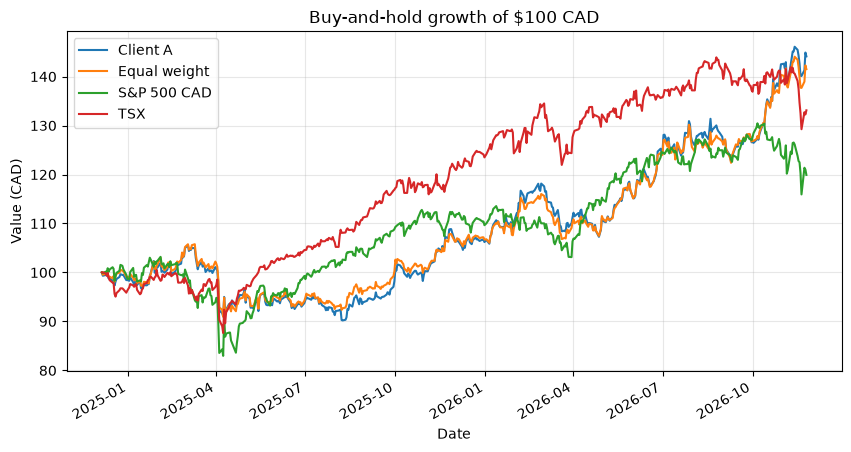

In [27]:
# Compare the same holdings at our weights and at equal weights
benchmarks = get_benchmarks_cad(prices.index, data["fx"], HISTORY_START, day)
tables = []
periods = []
chart = None

for days, label in [(LOOKBACK_DAYS, "Up to 1 year"), (LOOKBACK_DAYS * 2, "Up to 2 years")]:
    window = prices.loc[:day, chosen].tail(days + 1).ffill().dropna()
    if len(window) < 60:
        continue
    if label == "Up to 2 years" and len(window) <= LOOKBACK_DAYS:
        continue

    relative = window / window.iloc[0]
    growth = pd.DataFrame(index=window.index)
    growth["Client A"] = relative.mul(weights, axis=1).sum(axis=1)
    growth["Equal weight"] = relative.mean(axis=1)

    for market, name in [("US", "S&P 500 CAD"), ("CA", "TSX")]:
        b = benchmarks[market].reindex(window.index).ffill()
        if b.notna().all() and b.iloc[0] > 0:
            growth[name] = b / b.iloc[0]

    daily = growth.pct_change().dropna()
    summary = pd.DataFrame(index=growth.columns)
    summary["Return (%)"] = (growth.iloc[-1] - 1) * 100
    summary["Annual volatility (%)"] = daily.std() * np.sqrt(TRADING_DAYS_PER_YEAR) * 100
    summary["Worst drop (%)"] = (growth / growth.cummax() - 1).min() * 100
    summary["Start"] = window.index[0].date()
    summary["End"] = window.index[-1].date()
    summary["Days"] = len(daily)
    summary["Period"] = label
    tables.append(summary)
    periods.append(label)
    chart = growth

if not tables:
    raise ValueError("Not enough common history for an equal-weight comparison")

comparison_table = pd.concat(tables)
display(comparison_table.round(2))
for label in periods:
    part = comparison_table.loc[comparison_table["Period"] == label]
    a = part.loc["Client A", "Return (%)"]
    b = part.loc["Equal weight", "Return (%)"]
    print(label, "growth weights versus equal weights:", round(a - b, 2), "percentage points")
    
# Plot the growth of $100 CAD
(chart * 100).plot(figsize=(10, 5), title="Buy-and-hold growth of $100 CAD")
plt.ylabel("Value (CAD)")
plt.grid(alpha=0.3)
plt.show()

### Client B — Equal-weight comparison

Comparison period: 2025-12-01 to 2026-11-25 (252 trading days)
Client B holdings: 16 stocks


,Total return (%),Annualized return (%),Annualized volatility (%),Return / risk,Worst drop from peak (%),Best 5-day return (%),Worst 5-day return (%)
Client B,24.06,24.06,10.03,2.40,-7.03,3.81,-2.70
Equal-weight Client B,24.47,24.47,11.06,2.21,-6.43,4.67,-4.67
Equal-weight all eligible,22.92,22.92,13.36,1.72,-7.95,4.08,-6.31
S&P 500 (CAD),8.36,8.65,15.85,0.55,-11.13,5.29,-8.08
TSX,7.47,7.79,14.45,0.54,-10.99,4.17,-8.08


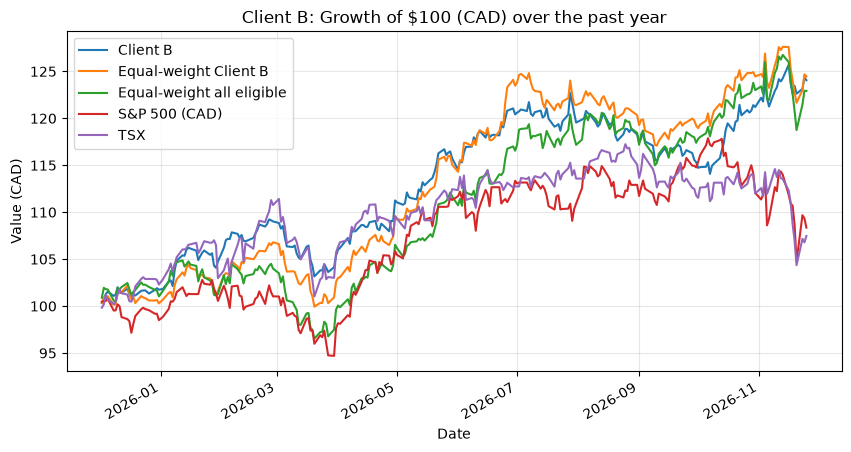

Our weighting vs equal weights on the same stocks: -0.41 percentage points of return, -1.03 points of volatility.
Our stock picks vs all eligible stocks (both equal weight): +1.55 percentage points of return, -2.30 points of volatility.


In [28]:
def performance(daily_returns):
    """Summary statistics for a Series of daily returns."""
    r = daily_returns.dropna()
    growth = (1 + r).cumprod()
    total = growth.iloc[-1] - 1
    ann_ret = (1 + total) ** (TRADING_DAYS_PER_YEAR / len(r)) - 1
    ann_vol = r.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    drawdown = (growth / growth.cummax() - 1).min()
    return pd.Series({
        "Total return (%)": total * 100,
        "Annualized return (%)": ann_ret * 100,
        "Annualized volatility (%)": ann_vol * 100,
        "Return / risk": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "Worst drop from peak (%)": drawdown * 100,
        "Best 5-day return (%)": ((1 + r).rolling(5).apply(np.prod, raw=True) - 1).max() * 100,
        "Worst 5-day return (%)": ((1 + r).rolling(5).apply(np.prod, raw=True) - 1).min() * 100,
    })

# Convert client b's weights dict to a normalized series
w_B = pd.Series(weights_B)
w_B = w_B / w_B.sum()

# CAD prices up to the purchase date
prices_B = data["prices_cad"].loc[:PURCHASE_DATE]
purchase_day = prices_B.index[-1]

window_B = prices_B.loc[:purchase_day].iloc[-(LOOKBACK_DAYS + 1):].ffill()
daily_B = window_B.pct_change().iloc[1:]

start_date = window_B.index[0] - pd.Timedelta(days=10)
end_date = window_B.index[-1] + pd.Timedelta(days=1)

sp500_usd = yf.download("^GSPC", start=start_date, end=end_date, progress=False)["Close"].squeeze()
tsx_cad = yf.download("^GSPTSE", start=start_date, end=end_date, progress=False)["Close"].squeeze()

fx = data["fx"].reindex(sp500_usd.index).ffill()

benchmarks = {
    "US": (sp500_usd * fx).ffill(),
    "CA": tsx_cad.ffill(), }

eligible_cols_B = [t for t in data["eligible"] if window_B[t].notna().all()]

comparison_returns_B = pd.DataFrame({
    "Client B": daily_B[w_B.index].mul(w_B, axis=1).sum(axis=1),
    "Equal-weight Client B": daily_B[w_B.index].mean(axis=1),
    "Equal-weight all eligible": daily_B[eligible_cols_B].mean(axis=1),
    "S&P 500 (CAD)": benchmarks["US"].reindex(window_B.index).pct_change().iloc[1:],
    "TSX": benchmarks["CA"].reindex(window_B.index).pct_change().iloc[1:],
})

comparison_table_B = comparison_returns_B.apply(performance).T.round(2)

print(f"Comparison period: {window_B.index[0].date()} to {window_B.index[-1].date()} ({len(daily_B)} trading days)")
print(f"Client B holdings: {len(w_B)} stocks")
if len(eligible_cols_B) < len(data["eligible"]):
    print("Left out of 'all eligible' (not a full year of prices):",
          sorted(set(data["eligible"]) - set(eligible_cols_B)))

display(comparison_table_B)
# Growth of $100 compound the daily returns
growth_B = (1 + comparison_returns_B.fillna(0)).cumprod() * 100
growth_B.plot(figsize=(10, 5), title="Client B: Growth of $100 (CAD) over the past year")
plt.ylabel("Value (CAD)")
plt.grid(alpha=0.3)
plt.show()
#effect of equal weight
diff_B = comparison_table_B.loc["Client B"] - comparison_table_B.loc["Equal-weight Client B"]
print(f"Our weighting vs equal weights on the same stocks: {diff_B['Total return (%)']:+.2f} percentage points "
      f"of return, {diff_B['Annualized volatility (%)']:+.2f} points of volatility.")
#effect of stock selection
diff2_B = comparison_table_B.loc["Equal-weight Client B"] - comparison_table_B.loc["Equal-weight all eligible"]
print(f"Our stock picks vs all eligible stocks (both equal weight): {diff2_B['Total return (%)']:+.2f} percentage points "
      f"of return, {diff2_B['Annualized volatility (%)']:+.2f} points of volatility.")

## Programmatic validation

Use Python (`assert` statements or a simple function are fine) to display whether **both** final portfolios pass each of the following checks:

- Selected tickers are valid and eligible.
- Number of stocks is between 10 and 20.
- No individual stock weight exceeds 15%.
- No single sector has more than 40% of portfolio value.
- Portfolio weights sum to 100%.
- Total stock purchases plus transaction fees do not exceed the applicable client budget.

Your code should run with the TAs’ ticker file without manually changing individual stock selections.

In [29]:
def validate_portfolio(portfolio, client, fees_cad):
    """Check a final portfolio against every rule. Returns a DataFrame of checks and prints a warning if any fail."""
    
    budget = CLIENT_BUDGETS[client]
    p = portfolio.set_index("Ticker")
    day = prices.index[-1]
    fx_day = float(data["fx"].loc[day])
    sector_w = p["Weight"].groupby(screening.loc[p.index, "Sector"]).sum()
    expected_value = p["Shares"] * p["Price"] * np.where(p["Currency"] == "USD", fx_day, 1.0)
    expected_fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * p["Shares"]).sum() * fx_day
    spent = p["Value"].sum() + fees_cad

    
    checks = [
        ("No missing values", not portfolio.isna().any().any()),
        ("No duplicate tickers", p.index.is_unique),
        ("All tickers eligible", set(p.index).issubset(data["eligible"])),
        (f"Between {MIN_STOCKS} and {MAX_STOCKS} stocks ({len(p)})", MIN_STOCKS <= len(p) <= MAX_STOCKS),
        ("All shares positive", (p["Shares"] > 0).all()),
        ("Weights add to 100%", np.isclose(p["Weight"].sum(), 1)),
        (f"Largest stock weight {p['Weight'].max():.2%} <= {MAX_STOCK_WEIGHT:.0%}",
         p["Weight"].max() <= MAX_STOCK_WEIGHT + 1e-9),
        (f"Largest sector weight {sector_w.max():.2%} <= {MAX_SECTOR_WEIGHT:.0%}",
         sector_w.max() <= MAX_SECTOR_WEIGHT + 1e-9),
        ("Value = Shares x Price x FX", np.allclose(p["Value"], expected_value, rtol=1e-6)),
        ("Weight = Value / total value", np.allclose(p["Weight"], p["Value"] / p["Value"].sum(), atol=1e-6)),
        (f"Fees match the fee rule (CAD {fees_cad:,.2f})", np.isclose(fees_cad, expected_fees, atol=0.01)),
        (f"Value + fees (CAD {spent:,.2f}) <= budget (CAD {budget:,.0f})", spent <= budget),
        (f"Budget used except CAD {budget - spent:,.2f}", budget - spent < 1),
        (f"Prices are from the purchase date ({PURCHASE_DATE.date()})", day == PURCHASE_DATE),
    ]
    
    
    result = pd.DataFrame(checks, columns=["Check", "Passed"])
    print(f"Client {client} validation:")
    print(result.to_string(index=False))
    failed = result.loc[~result["Passed"], "Check"].tolist()
    if failed:
        print("\nWARNING: failed checks:", failed)
    return result


#saving

def save_portfolio(portfolio, client):
    """Write the full portfolio table and a Ticker/Shares file for submission."""
    full_name = f"Portfolio_Final_{client}_Group_{GROUP_NUMBER}.csv"
    stocks_name = f"Stocks_Group_{GROUP_NUMBER}_{client}.csv"
    portfolio.to_csv(full_name, index=False)
    portfolio[["Ticker", "Shares"]].to_csv(stocks_name, index=False)
    print("Saved", full_name, "and", stocks_name)




## Final portfolio outputs

Display `Portfolio_Final_A` and `Portfolio_Final_B`, along with the budget reconciliation (purchases plus fees) for each. Generate `Stocks_Group_XX_A.csv` and `Stocks_Group_XX_B.csv` (replace `XX` with your team number). Each CSV must contain **only** the columns `Ticker` and `Shares`. The notebook must **generate** these CSV files when run, but you submit **only the notebook** to Dropbox.

In [30]:
# Validate both portfolios before saving either CSV
fees_B = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * Portfolio_Final_B["Shares"]).sum() * float(data["fx"].loc[PURCHASE_DATE])
validation_A = validate_portfolio(Portfolio_Final_A, "A", fees)
validation_B = validate_portfolio(Portfolio_Final_B, "B", fees_B)
if not validation_A["Passed"].all() or not validation_B["Passed"].all():
    raise ValueError("At least one portfolio validation check failed")

save_portfolio(Portfolio_Final_A, "A")
save_portfolio(Portfolio_Final_B, "B")

Client A validation:
                                                  Check  Passed
                                      No missing values    True
                                   No duplicate tickers    True
                                   All tickers eligible    True
                          Between 10 and 20 stocks (12)    True
                                    All shares positive    True
                                    Weights add to 100%    True
                     Largest stock weight 15.00% <= 15%    True
                    Largest sector weight 34.17% <= 40%    True
                            Value = Shares x Price x FX    True
                           Weight = Value / total value    True
                     Fees match the fee rule (CAD 5.25)    True
Value + fees (CAD 999,999.99) <= budget (CAD 1,000,000)    True
                            Budget used except CAD 0.01    True
         Prices are from the purchase date (2026-11-25)    True
Client B validation

## Contribution and AI Declaration

**The following team members made a meaningful contribution to this assignment:**

Enter the names of all contributing members below (one name per line):

**To the best of our knowledge, no generative AI was used in preparing this submission.**

List only members who made a meaningful contribution. Contact the instructor before the deadline if someone should be omitted or if the team cannot make the declaration.